BREAST CANCER PREDICTION PROJECT

Breast Cancer Classification Using Machine Learning

Project Overview

This project applies supervised machine learning to classify breast cell samples as benign or malignant using numerical measurements from the Wisconsin Breast Cancer dataset.

Objectives

Explore and understand the dataset using Pandas and visualization libraries.

Clean and prepare data for machine learning.

Train and compare classification algorithms.

Evaluate performance using accuracy, precision, recall, F1-score, and a confusion matrix.

Save a reusable machine learning pipeline.

Demonstrate predictions through a Streamlit application.

Technologies Used

Python

Pandas and NumPy

Matplotlib and Seaborn

Scikit-learn

Joblib

Streamlit

Jupyter Notebook

Methodology

Load and inspect the dataset.

Perform data quality checks and exploratory data analysis.

Separate input features from the diagnosis target.

Split the data into training and testing sets.

Train and compare classification models.

Use cross-validation to support model selection.

Evaluate the selected model on held-out test data.

Save the trained pipeline and demonstrate predictions.

Evaluation

Report the actual test-set accuracy, malignant-class precision and recall, F1-score, and confusion matrix after running the final evaluation. Do not insert unverified performance figures.

Running the Application

Install dependencies:

pip install -r requirements.txt

Start the app:

streamlit run app.py

Ensure the saved model files are available at the paths expected by the application.

Limitations

This project is an educational machine learning demonstration, not a clinically validated diagnostic system. Results depend on the dataset and evaluation method, and predictions must not replace professional medical assessment.

Future Improvements

Hyperparameter tuning

Independent dataset validation

Model interpretability

Automated tests and improved input validation

Responsible deployment and monitoring

In [1]:
import pandas as pd

Load the dataset

In [2]:
df=pd.read_csv(r"C:\Users\sajal\Desktop\ML\datasets\breast-cancer.csv")

In [3]:
pd.DataFrame(df)

,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.30010,0.14710,...,25.380,17.33,184.60,2019.0,0.16220,0.66560,0.7119,0.2654,0.4601,0.11890
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.08690,0.07017,...,24.990,23.41,158.80,1956.0,0.12380,0.18660,0.2416,0.1860,0.2750,0.08902
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.19740,0.12790,...,23.570,25.53,152.50,1709.0,0.14440,0.42450,0.4504,0.2430,0.3613,0.08758
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.24140,0.10520,...,14.910,26.50,98.87,567.7,0.20980,0.86630,0.6869,0.2575,0.6638,0.17300
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.19800,0.10430,...,22.540,16.67,152.20,1575.0,0.13740,0.20500,0.4000,0.1625,0.2364,0.07678
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
564,926424,M,21.56,22.39,142.00,1479.0,0.11100,0.11590,0.24390,0.13890,...,25.450,26.40,166.10,2027.0,0.14100,0.21130,0.4107,0.2216,0.2060,0.07115
565,926682,M,20.13,28.25,131.20,1261.0,0.09780,0.10340,0.14400,0.09791,...,23.690,38.25,155.00,1731.0,0.11660,0.19220,0.3215,0.1628,0.2572,0.06637
566,926954,M,16.60,28.08,108.30,858.1,0.08455,0.10230,0.09251,0.05302,...,18.980,34.12,126.70,1124.0,0.11390,0.30940,0.3403,0.1418,0.2218,0.07820
567,927241,M,20.60,29.33,140.10,1265.0,0.11780,0.27700,0.35140,0.15200,...,25.740,39.42,184.60,1821.0,0.16500,0.86810,0.9387,0.2650,0.4087,0.12400


Display the first five rows

In [4]:
df.head()

,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


Check the dataset size

In [7]:
print("Data Size:",df.shape)

Data Size: (569, 32)


Check column names

In [8]:
df.columns.to_list()

['id',
 'diagnosis',
 'radius_mean',
 'texture_mean',
 'perimeter_mean',
 'area_mean',
 'smoothness_mean',
 'compactness_mean',
 'concavity_mean',
 'concave points_mean',
 'symmetry_mean',
 'fractal_dimension_mean',
 'radius_se',
 'texture_se',
 'perimeter_se',
 'area_se',
 'smoothness_se',
 'compactness_se',
 'concavity_se',
 'concave points_se',
 'symmetry_se',
 'fractal_dimension_se',
 'radius_worst',
 'texture_worst',
 'perimeter_worst',
 'area_worst',
 'smoothness_worst',
 'compactness_worst',
 'concavity_worst',
 'concave points_worst',
 'symmetry_worst',
 'fractal_dimension_worst']

Check data types and missing values

In [10]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 32 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   id                       569 non-null    int64  
 1   diagnosis                569 non-null    object 
 2   radius_mean              569 non-null    float64
 3   texture_mean             569 non-null    float64
 4   perimeter_mean           569 non-null    float64
 5   area_mean                569 non-null    float64
 6   smoothness_mean          569 non-null    float64
 7   compactness_mean         569 non-null    float64
 8   concavity_mean           569 non-null    float64
 9   concave points_mean      569 non-null    float64
 10  symmetry_mean            569 non-null    float64
 11  fractal_dimension_mean   569 non-null    float64
 12  radius_se                569 non-null    float64
 13  texture_se               569 non-null    float64
 14  perimeter_se             5

What the project will predict
- Target (y): diagnosis
- Features (X): the numerical measurements used to predict the diagnosis.
- M: malignant.
- B: benign.

In [11]:
df.describe()

,id,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst
count,5.690000e+02,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,...,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000
mean,3.037183e+07,14.127292,19.289649,91.969033,654.889104,0.096360,0.104341,0.088799,0.048919,0.181162,...,16.269190,25.677223,107.261213,880.583128,0.132369,0.254265,0.272188,0.114606,0.290076,0.083946
std,1.250206e+08,3.524049,4.301036,24.298981,351.914129,0.014064,0.052813,0.079720,0.038803,0.027414,...,4.833242,6.146258,33.602542,569.356993,0.022832,0.157336,0.208624,0.065732,0.061867,0.018061
min,8.670000e+03,6.981000,9.710000,43.790000,143.500000,0.052630,0.019380,0.000000,0.000000,0.106000,...,7.930000,12.020000,50.410000,185.200000,0.071170,0.027290,0.000000,0.000000,0.156500,0.055040
25%,8.692180e+05,11.700000,16.170000,75.170000,420.300000,0.086370,0.064920,0.029560,0.020310,0.161900,...,13.010000,21.080000,84.110000,515.300000,0.116600,0.147200,0.114500,0.064930,0.250400,0.071460
50%,9.060240e+05,13.370000,18.840000,86.240000,551.100000,0.095870,0.092630,0.061540,0.033500,0.179200,...,14.970000,25.410000,97.660000,686.500000,0.131300,0.211900,0.226700,0.099930,0.282200,0.080040
75%,8.813129e+06,15.780000,21.800000,104.100000,782.700000,0.105300,0.130400,0.130700,0.074000,0.195700,...,18.790000,29.720000,125.400000,1084.000000,0.146000,0.339100,0.382900,0.161400,0.317900,0.092080
max,9.113205e+08,28.110000,39.280000,188.500000,2501.000000,0.163400,0.345400,0.426800,0.201200,0.304000,...,36.040000,49.540000,251.200000,4254.000000,0.222600,1.058000,1.252000,0.291000,0.663800,0.207500


Data Cleaning

Check missing values

In [12]:
df.isnull().sum()

id                         0
diagnosis                  0
radius_mean                0
texture_mean               0
perimeter_mean             0
area_mean                  0
smoothness_mean            0
compactness_mean           0
concavity_mean             0
concave points_mean        0
symmetry_mean              0
fractal_dimension_mean     0
radius_se                  0
texture_se                 0
perimeter_se               0
area_se                    0
smoothness_se              0
compactness_se             0
concavity_se               0
concave points_se          0
symmetry_se                0
fractal_dimension_se       0
radius_worst               0
texture_worst              0
perimeter_worst            0
area_worst                 0
smoothness_worst           0
compactness_worst          0
concavity_worst            0
concave points_worst       0
symmetry_worst             0
fractal_dimension_worst    0
dtype: int64

In [13]:
df.isnull().sum()[df.isnull().sum() > 0]

Series([], dtype: int64)

Check duplicate rows

In [14]:
df.duplicated().sum()

0

Check the target column

In [16]:
df["diagnosis"].value_counts()

diagnosis
B    357
M    212
Name: count, dtype: int64

To see the proportions as percentages:
This helps us understand whether the two classes are balanced or imbalanced.

In [17]:
print(df["diagnosis"].value_counts(normalize=True) * 100)

diagnosis
B    62.741652
M    37.258348
Name: proportion, dtype: float64


Check the ID column

In [18]:
print("Unique IDs:", df["id"].nunique())
print("Total rows:", len(df))

Unique IDs: 569
Total rows: 569


Exploratory Data Analysis (EDA)

Visualize the diagnosis distribution

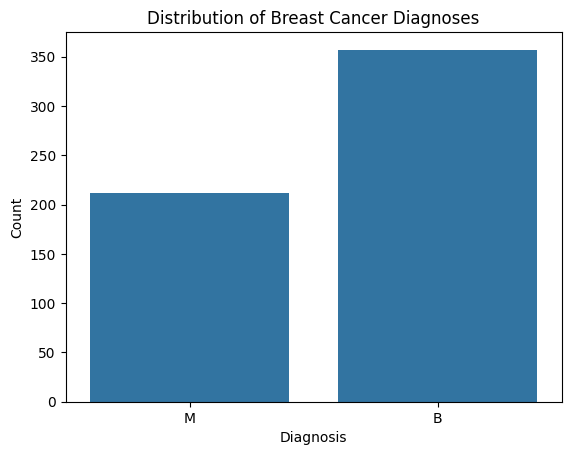

In [19]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.countplot(data=df, x="diagnosis")
plt.title("Distribution of Breast Cancer Diagnoses")
plt.xlabel("Diagnosis")
plt.ylabel("Count")
plt.show()

Compare a measurement between diagnoses

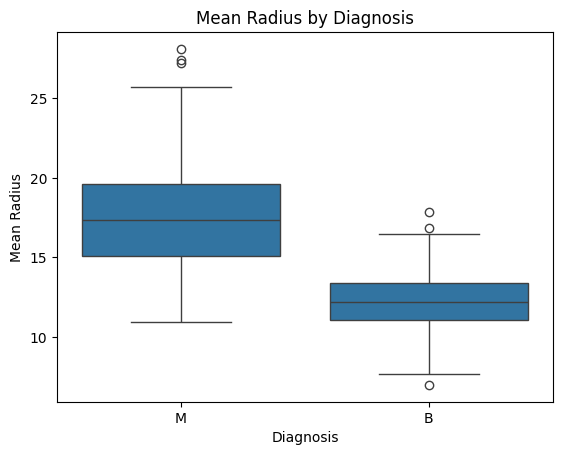

In [20]:
sns.boxplot(data=df, x="diagnosis", y="radius_mean")
plt.title("Mean Radius by Diagnosis")
plt.xlabel("Diagnosis")
plt.ylabel("Mean Radius")
plt.show()

- The line inside each box represents the median.
- The box represents the middle 50% of values.
- The whiskers show the spread under the boxplot's standard rules.
- Individual points beyond the whiskers may indicate potential outliers.

Compare multiple measurements

In [21]:
features = [
    "radius_mean",
    "texture_mean",
    "perimeter_mean"
]

print(df.groupby("diagnosis")[features].mean())

           radius_mean  texture_mean  perimeter_mean
diagnosis                                           
B            12.146524     17.914762       78.075406
M            17.462830     21.604906      115.365377


Data Preprocessing

Features (X): the input measurements used to make predictions.



Target (y): the diagnosis we want to predict (M or B).

In [22]:
# Remove the ID and diagnosis columns from the input features
X = df.drop(columns=["id", "diagnosis"])

# Store diagnosis as the target
y = df["diagnosis"]

# Check the dimensions
print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (569, 30)
Target shape: (569,)


In [23]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

Training features: (455, 30)
Testing features: (114, 30)


In [26]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

model = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(max_iter=5000))
])
model.fit(X_train, y_train)

Pipeline(steps=[('scaler', StandardScaler()),
                ('classifier', LogisticRegression(max_iter=5000))])

Model Training

In [27]:
y_pred = model.predict(X_test)

print(y_pred[:10])

['B' 'M' 'B' 'M' 'M' 'B' 'M' 'B' 'B' 'B']


Evaluate model accuracy

In [28]:
from sklearn.metrics import accuracy_score

accuracy = accuracy_score(y_test, y_pred)

print("Model Accuracy:", accuracy)
print("Model Accuracy (%):", accuracy * 100)

Model Accuracy: 0.9649122807017544
Model Accuracy (%): 96.49122807017544


In [29]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           B       0.96      0.99      0.97        72
           M       0.97      0.93      0.95        42

    accuracy                           0.96       114
   macro avg       0.97      0.96      0.96       114
weighted avg       0.97      0.96      0.96       114



Precision: Of the cases predicted as a particular class, how many were correct?



Recall: Of the actual cases in a class, how many did the model identify?



F1-score: A balance between precision and recall.



Support: The number of actual test examples in each class.

Create a confusion matrix

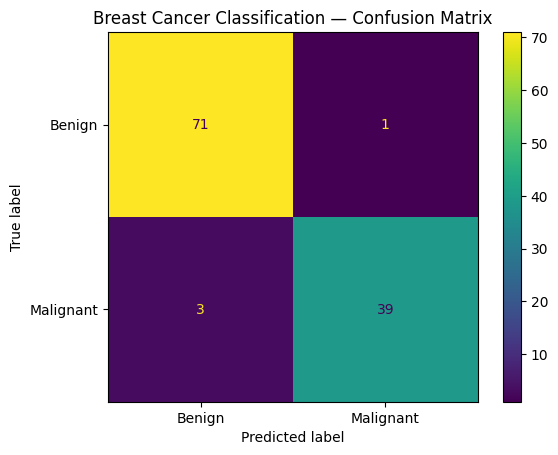

In [30]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    labels=["B", "M"],
    display_labels=["Benign", "Malignant"]
)

plt.title("Breast Cancer Classification — Confusion Matrix")
plt.show()

Train and compare multiple models

We'll compare three models:
- Logistic Regression
- Decision Tree
- Random Forest

In [31]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, recall_score, f1_score

In [32]:
models = {
    "Logistic Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("classifier", LogisticRegression(max_iter=5000))
    ]),

    "Decision Tree": DecisionTreeClassifier(
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        random_state=42
    )
    }

results = []

for name, clf in models.items():
    clf.fit(X_train, y_train)
    predictions = clf.predict(X_test)

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Malignant Recall": recall_score(
            y_test, predictions, pos_label="M"
        ),
        "Malignant F1": f1_score(
            y_test, predictions, pos_label="M"
        )
    })

results_df = pd.DataFrame(results)
print(results_df.sort_values("Malignant Recall", ascending=False))

                 Model  Accuracy  Malignant Recall  Malignant F1
0  Logistic Regression  0.964912          0.928571      0.951220
1        Decision Tree  0.929825          0.904762      0.904762
2        Random Forest  0.964912          0.904762      0.950000


Explanation of the code
1. Define the models

models stores three different algorithms. Logistic Regression uses StandardScaler; Decision Tree and Random Forest don't require standard scaling.

2. Train each model

clf.fit(X_train, y_train) teaches each model using the training data.

3. Make predictions

clf.predict(X_test) predicts the diagnosis for unseen test examples.

4. Compare metrics
- Accuracy: overall proportion of correct predictions.
- Malignant Recall: proportion of actual malignant cases correctly identified.
- Malignant F1: balances malignant-class precision and recall.
5. Sort the results

We sort by malignant recall so you can first inspect which models identified the largest proportion of malignant cases. We must also consider precision, false negatives, and validation results before choosing a final model.

Visualize the comparison

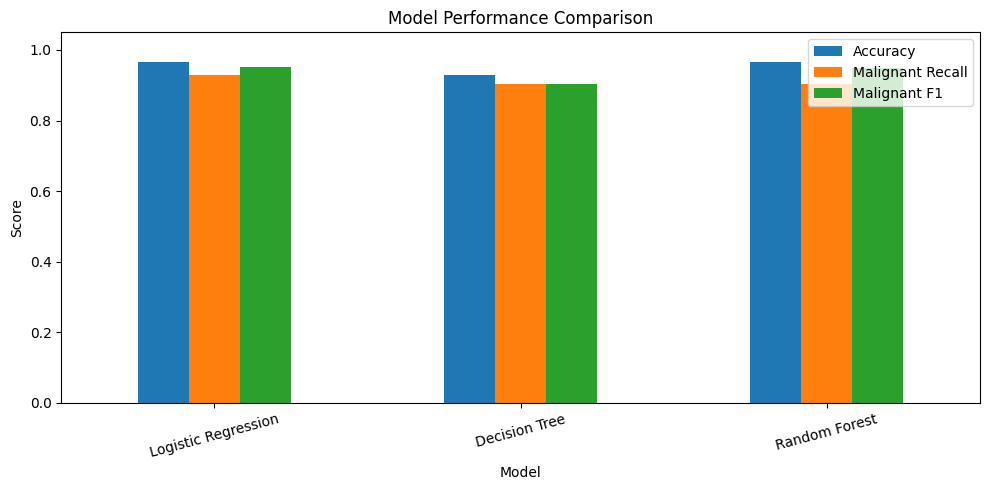

In [33]:
results_df.set_index("Model")[
    ["Accuracy", "Malignant Recall", "Malignant F1"]
].plot(kind="bar", figsize=(10, 5))

plt.title("Model Performance Comparison")
plt.ylabel("Score")
plt.ylim(0, 1.05)
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

This chart compares the three metrics for each model. A higher score is better for each of these metrics, but the appropriate balance depends on the project's objectives.

Compare models using cross-validation

In [35]:
from sklearn.model_selection import StratifiedKFold, cross_validate
models = {
    "Logistic Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("classifier", LogisticRegression(max_iter=5000))
    ]),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        random_state=42
    )
}

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

scoring = {
    "accuracy": "accuracy",
    "precision": "precision_macro",
    "recall": "recall_macro",
    "f1": "f1_macro"
}

cv_results = []

for name, clf in models.items():
    scores = cross_validate(
        clf,
        X_train,
        y_train,
        cv=cv,
        scoring=scoring
    )

    cv_results.append({
        "Model": name,
        "Mean Accuracy": scores["test_accuracy"].mean(),
        "Mean Precision": scores["test_precision"].mean(),
        "Mean Recall": scores["test_recall"].mean(),
        "Mean F1": scores["test_f1"].mean()
    })

cv_results_df = pd.DataFrame(cv_results)

print(
    cv_results_df.sort_values(
        "Mean F1",
        ascending=False
    ).round(4)
)

                 Model  Mean Accuracy  Mean Precision  Mean Recall  Mean F1
0  Logistic Regression         0.9736          0.9751       0.9695   0.9716
2        Random Forest         0.9626          0.9632       0.9571   0.9597
1        Decision Tree         0.9231          0.9188       0.9172   0.9175


In [36]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

final_model = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(max_iter=5000))
])

final_model.fit(X_train, y_train)

print("Final model training completed!")

Final model training completed!



Pipeline() combines scaling and classification into one workflow.



StandardScaler() standardizes numerical features.



LogisticRegression() learns patterns associated with the diagnosis labels.



final_model.fit() trains the pipeline on the training dataset.

Evaluate on the test set

In [37]:
from sklearn.metrics import classification_report

y_pred_final = final_model.predict(X_test)

print(classification_report(
    y_test,
    y_pred_final,
    labels=["B", "M"],
    target_names=["Benign", "Malignant"]
))

              precision    recall  f1-score   support

      Benign       0.96      0.99      0.97        72
   Malignant       0.97      0.93      0.95        42

    accuracy                           0.96       114
   macro avg       0.97      0.96      0.96       114
weighted avg       0.97      0.96      0.96       114



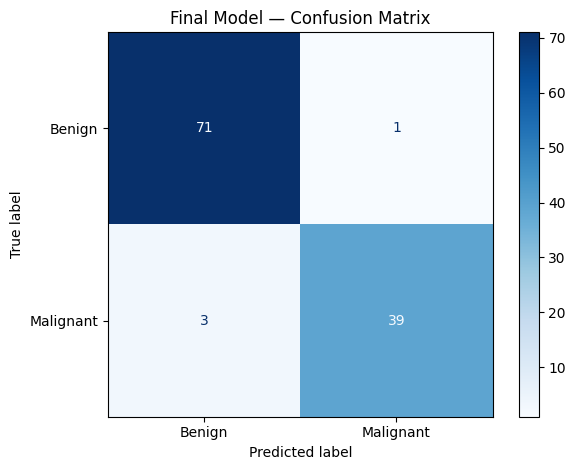

In [38]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_final,
    labels=["B", "M"],
    display_labels=["Benign", "Malignant"],
    cmap="Blues"
)

plt.title("Final Model — Confusion Matrix")
plt.tight_layout()
plt.show()

Save the trained model

In [39]:
import joblib

joblib.dump(final_model, "breast_cancer_model.pkl")

print("Model saved successfully!")

Model saved successfully!


Load the saved model

In [40]:
loaded_model = joblib.load("breast_cancer_model.pkl")

print("Saved model loaded successfully!")

Saved model loaded successfully!


Verify that it works

In [41]:
original_predictions = final_model.predict(X_test)
loaded_predictions = loaded_model.predict(X_test)

print(
    "Predictions match:",
    (original_predictions == loaded_predictions).all()
)

Predictions match: True


Save the feature names

In [42]:
feature_names = X.columns.tolist()

joblib.dump(feature_names, "breast_cancer_features.pkl")

print("Feature names saved successfully!")

Feature names saved successfully!


The Breast Cancer Classification project demonstrates the end-to-end application of machine learning to a binary classification problem using the Wisconsin Breast Cancer dataset. The objective was to develop a model that classifies breast cell samples as benign (B) or malignant (M) based on numerical measurements of cell nuclei.

The project involved data loading, data cleaning, exploratory data analysis (EDA), feature selection, training and testing data splitting, and model development using Scikit-learn. Multiple classification algorithms, including Logistic Regression, Decision Tree, and Random Forest, were considered and evaluated using performance metrics such as accuracy, precision, recall, F1-score, and a confusion matrix. Cross-validation was also used to compare model performance more reliably.

A preprocessing and prediction pipeline was created, and the trained model was saved using Joblib for reuse. A simple Streamlit application was developed to demonstrate how the model can be used to generate predictions from numerical input features.

Through this project, practical skills in Python, Pandas, data visualization, machine learning, model evaluation, and application development were applied. The project provides a foundation for building and deploying machine learning applications.

Future improvements could include more extensive hyperparameter tuning, further validation on independent datasets, improved input validation, model interpretability, and responsible deployment practices.

This project is intended for educational purposes and is not a clinically validated medical diagnostic system. Its predictions should not be used as a substitute for professional medical assessment.